In [1]:
from correlation_stability import run_stability_analysis
import scanpy as sc
from run_dgcna_correlation import run_dgcna_analysis
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:

adata=sc.read_loom('Integrated_betas.loom') 
adata.obs_names=adata.obs.obs_names
adata.var_names=adata.var.gene_name



C:\Users\Leo\anaconda3\Lib\functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
C:\Users\Leo\anaconda3\Lib\functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [3]:
#adata=adata[adata.obs.Disease=='T2D'].copy()

import numpy as np

np.random.seed(0)  # optional, for reproducibility
n = adata.n_obs
groups = np.array(['A'] * (n // 2) + ['B'] * (n - n // 2))
np.random.shuffle(groups)

adata.obs['Group'] = groups

In [4]:
sel_genes=pd.read_excel("sel_genes.xlsx")
ndcg_genes=sel_genes.Gene_name.unique()
glyco=sel_genes[sel_genes.Module=='(6) Glycolysis'].Gene_name.values

In [5]:
import numpy as np
import pandas as pd
from itertools import combinations
import random

# Keep ALL subjects only

# Subject/donor ID
subject_col = 'Donor'  # <-- change if needed

subjects = np.array(adata.obs[subject_col].unique())

assert len(subjects) == 17, f"Expected 17 subjects, found {len(subjects)}"

summary = []

# 9-vs-8 splits
# Keep only one of each A/B vs B/A pair
splits = [
    split for split in combinations(subjects, 9)
    if subjects[0] in split
]


# Pick only 100 splits
n_random_splits = 30
random_seed = 42
random.seed(random_seed)
splits = random.sample(splits, min(n_random_splits, len(splits)))


print(f"Running {len(splits)} unique subject splits...")

for it, group_A_subjects in enumerate(splits):

    group_A_subjects = set(group_A_subjects)

    # Assign all cells from each subject to the same group
    adata.obs['Group'] = np.where(
        adata.obs[subject_col].isin(group_A_subjects),
        'A',
        'B'
    )

    # Run complete dGCNA pipeline
    results = run_dgcna_analysis(
        adata,
        genes=ndcg_genes,
        disease_col='Group',
        t2d_value='B',
        ctrl_value='A',
        n_bootstrap=512,
        threshold=0.975
    )

    corr = results['filtered_net']

    # Upper triangle only
    upper = np.triu(corr.values, k=1)
    sig_delta = np.abs(upper[upper != 0])

    # Total number of tested gene pairs
    n_genes = corr.shape[0]
    n_total = n_genes * (n_genes - 1) // 2

    summary.append({
        'iteration': it + 1,
        'group_A': ','.join(sorted(group_A_subjects)),
        'group_B': ','.join(sorted(set(subjects) - group_A_subjects)),
        'n_sig': len(sig_delta),
        'pct_sig': 100 * len(sig_delta) / n_total,
        'median_abs_delta_r': (
            np.median(sig_delta) if len(sig_delta) else np.nan
        )
    })

summary_df = pd.DataFrame(summary)

# Save results
summary_df.to_csv(
    "dGCNA_random_9vs8_splits.csv",
    index=False
)

print(f"Completed {len(summary_df)} unique 9-vs-8 splits.")

Running 30 unique subject splits...
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 454, donors: 8, genes: 664
Cells: 584, donors: 9, genes: 664

=== Step 2: Building differential network ===
T2D cells: 454, Control cells: 584

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [01:42<00:00,  5.00it/s]


Significant edges: 13667 / 220116 (6.2%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 495, donors: 8, genes: 664
Cells: 543, donors: 9, genes: 664

=== Step 2: Building differential network ===
T2D cells: 495, Control cells: 543

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [01:47<00:00,  4.76it/s]


Significant edges: 7677 / 220116 (3.5%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 498, donors: 8, genes: 664
Cells: 540, donors: 9, genes: 664

=== Step 2: Building differential network ===
T2D cells: 498, Control cells: 540

=== Step 3: Bootstrap filtering ===


...

Significant edges: 12202 / 220116 (5.5%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 493, donors: 8, genes: 664
Cells: 545, donors: 9, genes: 664

=== Step 2: Building differential network ===
T2D cells: 493, Control cells: 545

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [01:07<00:00,  7.58it/s]


Significant edges: 10124 / 220116 (4.6%)
Using 664 / 671 specified genes

=== Step 1: Computing LMM residuals (per condition) ===
Cells: 505, donors: 8, genes: 664
Cells: 533, donors: 9, genes: 664

=== Step 2: Building differential network ===
T2D cells: 505, Control cells: 533

=== Step 3: Bootstrap filtering ===


Random donor groups (with replacement): 100%|████████████████████████████████████████| 512/512 [01:08<00:00,  7.46it/s]

Significant edges: 12493 / 220116 (5.7%)
Completed 30 unique 9-vs-8 splits.


In [6]:

# Summary
print("\nSummary:")
print(f"Number of unique splits: {len(summary_df)}")
print(
    f"Significant edges — median: "
    f"{summary_df['n_sig'].median():.0f}"
)
print(
    f"Significant edges — range: "
    f"{summary_df['n_sig'].min():.0f}–"
    f"{summary_df['n_sig'].max():.0f}"
)
print(
    f"Percentage significant — median: "
    f"{summary_df['pct_sig'].median():.1f}%"
)
print(
    f"Percentage significant — range: "
    f"{summary_df['pct_sig'].min():.1f}–"
    f"{summary_df['pct_sig'].max():.1f}%"
)
print(
    f"Median |Δr| across splits: "
    f"{summary_df['median_abs_delta_r'].median():.3f}"
)



Summary:
Number of unique splits: 30
Significant edges — median: 10964
Significant edges — range: 7677–31185
Percentage significant — median: 5.0%
Percentage significant — range: 3.5–14.2%
Median |Δr| across splits: 0.166


C:\Users\Leo\AppData\Local\Temp\ipykernel_2936\614065230.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


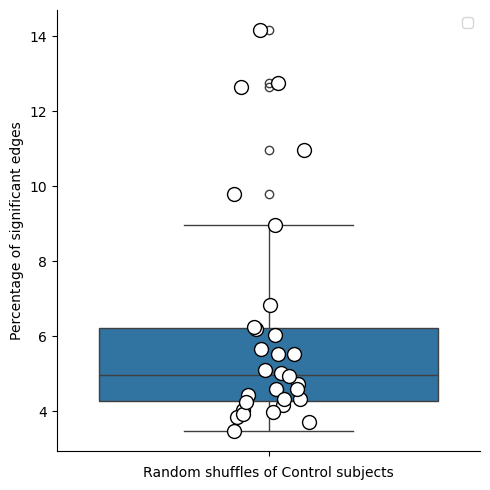

In [7]:
# Distribution of % of significant edges on random shuffles of control donors
fig, ax = plt.subplots(figsize=(5, 5))

sns.boxplot(summary_df, y='pct_sig')
sns.stripplot(summary_df, y='pct_sig',  linewidth=1, color='w', s=10, edgecolor='k')

ax.set_xlabel(f'Random shuffles of Control subjects')
ax.set_ylabel(f'Percentage of significant edges')
#ax.set_title(f'CTRL Sample ({largest_ctrl_donor}, n={largest_ctrl_n})\nr = {r_resid_ctrl:.3f}')
ax.spines[['top', 'right']].set_visible(False)
ax.legend()
sns.despine()
plt.tight_layout()
#plt.savefig('Figure3/pct_significant_T2D.png')
#plt.savefig('Figure3/pct_significant_T2D.svg')

In [8]:
summary_df

,iteration,group_A,group_B,n_sig,pct_sig,median_abs_delta_r
0,1,"HP1525901,HP1529801T2D,HP1601201T2D,HP1605601T...","HP1602301T2D,HP1606401T2D,HP1711701T2D,HP17146...",13667,6.208999,0.169158
1,2,"HP1529801T2D,HP1606401T2D,HP1711001,HP1714601,...","HP1525901,HP1601201T2D,HP1602301T2D,HP1605601T...",7677,3.487706,0.161069
2,3,"HP1525901,HP1605601T2D,HP1711001,HP1711701T2D,...","HP1529801T2D,HP1601201T2D,HP1602301T2D,HP16064...",9526,4.327718,0.160261
3,4,"HP1529801T2D,HP1601201T2D,HP1711001,HP1711701T...","HP1525901,HP1602301T2D,HP1605601T2D,HP1606401T...",9167,4.164622,0.160014
4,5,"HP1529801T2D,HP1605601T2D,HP1606401T2D,HP17117...","HP1525901,HP1601201T2D,HP1602301T2D,HP1711001,...",8892,4.039688,0.167196
5,6,"HP1525901,HP1601201T2D,HP1605601T2D,HP1711001,...","HP1529801T2D,HP1602301T2D,HP1606401T2D,HP17117...",24127,10.961039,0.177699
6,7,"HP1605601T2D,HP1606401T2D,HP1711701T2D,HP17146...","HP1525901,HP1529801T2D,HP1601201T2D,HP1602301T...",13280,6.033183,0.171470
7,8,"HP1529801T2D,HP1606401T2D,HP1711001,HP1714601,...","HP1525901,HP1601201T2D,HP1602301T2D,HP1605601T...",11259,5.115030,0.168701
8,9,"HP1525901,HP1529801T2D,HP1601201T2D,HP1605601T...","HP1602301T2D,HP1606401T2D,HP1711701T2D,HP17146...",11062,5.025532,0.164365
9,10,"HP1529801T2D,HP1602301T2D,HP1711701T2D,Sample1...","HP1525901,HP1601201T2D,HP1605601T2D,HP1606401T...",9791,4.448109,0.162718
